# APS2 — Regressão do preço de anúncios Airbnb em Nova York

**Disciplina:** Machine Learning (Insper)
**Grupo:** Maria Eduarda Oliveira Galdino e Tomaz Santos Almeida
**Dataset:** New York City Airbnb Open Data (`AB_NYC_2019.csv`)
**Problema:** regressão — prever o preço anunciado por noite (`price`, em USD)
**Prazo da APS2 na rubrica:** 26/10 (ano não informado no enunciado)
**Data efetiva de entrega:** a preencher pelo grupo no momento da submissão
**Data de elaboração:** 28/10/2026
**Orientações da etapa:** `Projeto_de_Machine_Learning (1).ipynb` (seção APS2)
**Etapa anterior:** `Meu_projeto_EDA_ML_revisado (2).ipynb` (APS1, EDA)

Esta etapa reutiliza o pré-processamento da APS 1 (`src/nyc_airbnb_eda/preprocessing.py`: o mesmo `ColumnTransformer` e o mesmo split 80/20, `random_state=42`, estratificado por decis de preço). A escolha de modelo, de hiperparâmetros e da transformação do alvo usa somente treino e validação cruzada; o teste só aparece na seção 7.

> **Tempo de execução:** rodar o notebook inteiro leva cerca de 21 minutos em um PC com 20 núcleos; as buscas da Random Forest e o SHAP são as partes mais pesadas. O notebook precisa de `data/raw/AB_NYC_2019.csv` e das bibliotecas de `requirements.txt` (inclui seaborn e shap).

**Resumo.** O modelo final é uma Random Forest treinada com `log1p(price)`. Ela tem MAE de US$ 55,81 na validação cruzada e US$ 57,53 no teste, contra US$ 85,93 do Dummy no teste (33,1% menos erro). O erro se concentra nos anúncios mais caros e em anúncios sem avaliações, e foi 4,7% maior na análise complementar com folds separados por anfitrião. Esse experimento não determina o erro exato para futuros anfitriões novos.

## 1. Objetivo e protocolo de avaliação

Comparamos um baseline Dummy, uma regressão linear regularizada (Ridge) e um ensemble de árvores (Random Forest). A métrica principal é o **MAE (erro absoluto médio), em dólares**: um MAE de 50 significa erro absoluto médio de US$ 50 por anúncio. Escolhemos o MAE porque ele fica na unidade do problema e pesa menos os poucos anúncios de preço extremo do que o RMSE; como o preço tem cauda longa, essa robustez ajuda a ler o desempenho típico.

A comparação e todas as buscas de hiperparâmetros usam validação cruzada de cinco folds (`KFold` com embaralhamento e `random_state=42`) **somente no conjunto de treino**, com os mesmos folds para todos os modelos. O holdout de teste da APS 1 só é usado na avaliação final, depois que o modelo já foi escolhido.

In [1]:
import json
import os
import sys
import time
import warnings
from pathlib import Path

START_TIME = time.time()
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    raise FileNotFoundError("Abra este notebook na pasta raiz do repositório.")

os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".matplotlib"))
sys.path.insert(0, str(PROJECT_ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from IPython.display import display
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import (
    GridSearchCV,
    GroupKFold,
    KFold,
    RandomizedSearchCV,
    cross_val_score,
    learning_curve,
)

from nyc_airbnb_eda.modeling import (
    build_log_target_pipeline,
    build_model_pipeline,
    display_feature_name,
    get_preprocessed_feature_names,
    original_feature_name,
)
from nyc_airbnb_eda.preprocessing import split_data

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 10})
AZUL, VERDE, LARANJA = "#315f70", "#679e9a", "#d17b57"

SEED = 42
OUTPUT_DIR = PROJECT_ROOT / "reports" / "figures" / "aps2"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "AB_NYC_2019.csv"
RESULTS = {}  # números finais; salvos em reports/aps2_results.json no fim do notebook

print("Python:", sys.version.split()[0])
print("scikit-learn:", __import__("sklearn").__version__)
print("seaborn:", sns.__version__)
print("SHAP:", shap.__version__)
print("CSV:", DATA_PATH)

Python: 3.11.9
scikit-learn: 1.8.0
seaborn: 0.13.2
SHAP: 0.51.0
CSV: C:\Users\tomaz\OneDrive\Documentos\Insper\4° sem\ML (Machine Learning)\APS\nyc-airbnb-eda-pipeline\data\raw\AB_NYC_2019.csv


C:\Users\tomaz\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Leitura e auditoria da base

Os 11 anúncios com `price = 0` são removidos conforme a decisão da APS 1. Os 14 casos com `minimum_nights > 365` são mantidos (a APS 1 os classificou como potencialmente inconsistentes, mas plausíveis para estadias longas); a seção 10 mede o efeito dessa escolha. A coluna `host_id` é preservada só para auditar a estrutura dos grupos: o pré-processador não a usa como preditora.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"CSV não encontrado em {DATA_PATH}. Coloque AB_NYC_2019.csv em data/raw/.")

df = pd.read_csv(DATA_PATH)
print(f"Base original: {df.shape[0]:,} linhas × {df.shape[1]} colunas")
print("Colunas:", ", ".join(df.columns))
print("Preços não positivos:", int((df["price"] <= 0).sum()))
print("minimum_nights > 365:", int((df["minimum_nights"] > 365).sum()))
display(
    pd.DataFrame({"ausentes": df.isna().sum(), "%": (df.isna().mean() * 100).round(2)})
    .query("ausentes > 0")
    .sort_values("ausentes", ascending=False)
)
RESULTS["dados"] = {
    "linhas": int(df.shape[0]),
    "colunas": int(df.shape[1]),
    "preco_nao_positivo": int((df["price"] <= 0).sum()),
    "minimum_nights_acima_365": int((df["minimum_nights"] > 365).sum()),
}

Base original: 48,895 linhas × 16 colunas
Colunas: id, name, host_id, host_name, neighbourhood_group, neighbourhood, latitude, longitude, room_type, price, minimum_nights, number_of_reviews, last_review, reviews_per_month, calculated_host_listings_count, availability_365
Preços não positivos: 11
minimum_nights > 365: 14


,ausentes,%
reviews_per_month,10052,20.56
last_review,10052,20.56
host_name,21,0.04
name,16,0.03


## 3. Divisão treino/teste e risco de dependência por anfitrião

`split_data` remove o alvo inválido, separa 80%/20% com `random_state=42` e estratifica por decis de preço, exatamente como na APS 1. O teste não participa de validação cruzada, busca de hiperparâmetros nem da escolha da transformação do alvo.

Um anfitrião pode ter vários anúncios, então uma divisão aleatória por linha pode colocar anúncios do mesmo anfitrião nos dois lados. Calculamos essa sobreposição aqui e medimos o efeito na seção 11.

In [3]:
X_train, X_test, y_train, y_test = split_data(df, test_size=0.2, random_state=SEED)
print(f"Treino: {X_train.shape[0]:,} anúncios; teste: {X_test.shape[0]:,} anúncios")
print(f"Mediana de price — treino/teste: ${y_train.median():.2f} / ${y_test.median():.2f}")

test_hosts = set(X_test["host_id"])
shared_hosts = set(X_train["host_id"]) & test_hosts
overlap_pct = 100 * len(shared_hosts) / len(test_hosts)
print(
    f"Anfitriões únicos no teste: {len(test_hosts):,}; "
    f"também presentes no treino: {len(shared_hosts):,} ({overlap_pct:.1f}%)"
)
test_rows_shared = float(X_test["host_id"].isin(set(X_train["host_id"])).mean() * 100)
print(f"Anúncios do teste cujo anfitrião também está no treino: {test_rows_shared:.1f}%")
RESULTS["split"] = {
    "treino": int(len(X_train)),
    "teste": int(len(X_test)),
    "hosts_teste": len(test_hosts),
    "hosts_em_comum": len(shared_hosts),
    "hosts_em_comum_pct": float(overlap_pct),
    "anuncios_teste_host_no_treino_pct": test_rows_shared,
}

Treino: 39,107 anúncios; teste: 9,777 anúncios
Mediana de price — treino/teste: $106.00 / $106.00
Anfitriões únicos no teste: 8,727; também presentes no treino: 2,142 (24.5%)
Anúncios do teste cujo anfitrião também está no treino: 31.0%


## 4. Modelos, métrica e validação cruzada

Todos os estimadores recebem os dados ainda sem processar. O pré-processador da APS 1 está dentro de cada `Pipeline`, então imputação, escala e categorias são reaprendidas dentro de cada fold e nenhuma informação do fold de validação vaza para o ajuste.

- **Dummy:** prevê sempre a mediana do preço do treino. É a referência mínima que qualquer modelo precisa vencer.
- **Ridge:** modelo linear com regularização L2; ajustamos `alpha`.
- **Random Forest:** ensemble de árvores; ajustamos profundidade, tamanho mínimo de folha e fração de atributos por divisão. O número de árvores fica fixo em 200 (mais árvores só reduzem a variância das previsões e aumentam o tempo).

In [4]:
CV = KFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = "neg_mean_absolute_error"

RIDGE_PARAMS = {"alpha": np.logspace(-3, 3, 13)}
RF_PARAMS = {
    "max_depth": [10, 15, 20, None],
    "min_samples_leaf": [1, 2, 3, 5, 8, 12],
    "max_features": [0.1, 0.2, 0.33, 0.5, 0.75, 1.0],
}
RF_ITER = 20  # sorteia 20 das 144 combinações; mesma amostra (random_state) em todas as buscas


def make_search(estimator, params, log_target=False, n_iter=None):
    # Monta a busca no pipeline completo (pré-processador + modelo). Com log_target=True o
    # alvo vira log1p(price) só dentro do treino de cada fold; o MAE segue em dólares.
    if log_target:
        base, prefix = build_log_target_pipeline(estimator), "regressor__model__"
    else:
        base, prefix = build_model_pipeline(estimator), "model__"
    grid = {prefix + name: values for name, values in params.items()}
    common = dict(scoring=SCORING, cv=CV, refit=True, n_jobs=1)  # paralelismo fica dentro da floresta
    if n_iter:
        return RandomizedSearchCV(base, grid, n_iter=n_iter, random_state=SEED, **common)
    return GridSearchCV(base, grid, **common)


def fold_mae(search):
    # MAE de cada fold para a melhor configuração (desvio com ddof=1, igual para todos os modelos)
    return -np.array([
        search.cv_results_[f"split{k}_test_score"][search.best_index_] for k in range(CV.get_n_splits())
    ])


def clean_params(search):
    return {key.split("__")[-1]: value for key, value in search.best_params_.items()}


def new_forest():
    return RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1)

### 4.1 Baseline Dummy

In [5]:
dummy_pipeline = build_model_pipeline(DummyRegressor(strategy="median"))
dummy_folds = -cross_val_score(dummy_pipeline, X_train, y_train, scoring=SCORING, cv=CV)
print(f"Dummy (mediana) — MAE CV: ${dummy_folds.mean():.2f} ± ${dummy_folds.std(ddof=1):.2f}")
RESULTS["dummy"] = {"mae_cv": float(dummy_folds.mean()), "desvio_cv": float(dummy_folds.std(ddof=1))}

Dummy (mediana) — MAE CV: $83.66 ± $1.36


### 4.2 Ridge: busca da regularização

A busca escolhe `alpha` pela média do MAE nos cinco folds. O Ridge minimiza erro quadrático, mas é avaliado e escolhido pelo MAE, a métrica do problema.

In [6]:
t0 = time.time()
ridge_search = make_search(Ridge(), RIDGE_PARAMS).fit(X_train, y_train)
print("Melhor alpha:", clean_params(ridge_search)["alpha"])
print(f"Ridge — MAE CV: ${-ridge_search.best_score_:.2f} ± ${fold_mae(ridge_search).std(ddof=1):.2f}")
print(f"Tempo da busca: {time.time() - t0:.0f} s")

Melhor alpha: 100.0
Ridge — MAE CV: $70.78 ± $1.49
Tempo da busca: 13 s


### 4.3 Random Forest: busca do ensemble

`RandomizedSearchCV` sorteia 20 das 144 combinações da grade, com o mesmo MAE e os mesmos folds do Ridge. A grade tem valores dos dois lados do que esperamos ser o melhor para que a escolha não fique presa na borda; conferimos isso na seção 5.3.

In [7]:
t0 = time.time()
forest_search = make_search(new_forest(), RF_PARAMS, n_iter=RF_ITER).fit(X_train, y_train)
print("Melhores hiperparâmetros:", clean_params(forest_search))
print(f"Random Forest — MAE CV: ${-forest_search.best_score_:.2f} ± ${fold_mae(forest_search).std(ddof=1):.2f}")
print(f"Tempo da busca: {time.time() - t0:.0f} s")

Melhores hiperparâmetros: {'min_samples_leaf': 5, 'max_features': 0.2, 'max_depth': None}
Random Forest — MAE CV: $63.42 ± $1.85
Tempo da busca: 262 s


### 4.4 Comparação inicial

In [8]:
initial = pd.DataFrame([
    {"modelo": "Dummy (mediana)", "MAE CV (US$)": dummy_folds.mean(), "desvio entre folds (US$)": dummy_folds.std(ddof=1)},
    {"modelo": "Ridge", "MAE CV (US$)": -ridge_search.best_score_, "desvio entre folds (US$)": fold_mae(ridge_search).std(ddof=1)},
    {"modelo": "Random Forest", "MAE CV (US$)": -forest_search.best_score_, "desvio entre folds (US$)": fold_mae(forest_search).std(ddof=1)},
]).sort_values("MAE CV (US$)").reset_index(drop=True)
display(initial.style.format({"MAE CV (US$)": "${:,.2f}", "desvio entre folds (US$)": "${:,.2f}"}))
RESULTS["inicial"] = {
    "ridge": {"mae_cv": float(-ridge_search.best_score_), "desvio_cv": float(fold_mae(ridge_search).std(ddof=1)), **{k: float(v) for k, v in clean_params(ridge_search).items()}},
    "rf": {"mae_cv": float(-forest_search.best_score_), "desvio_cv": float(fold_mae(forest_search).std(ddof=1)), "params": {k: (None if v is None else float(v)) for k, v in clean_params(forest_search).items()}},
}

,modelo,MAE CV (US$),desvio entre folds (US$)
0,Random Forest,$63.42,$1.85
1,Ridge,$70.78,$1.49
2,Dummy (mediana),$83.66,$1.36


**O que a comparação mostra.** O Dummy erra US$ 83,66 por anúncio em média; é o piso que qualquer modelo precisa bater. O Ridge reduz o erro para US$ 70,78 e a Random Forest para US$ 63,42 (24,2% abaixo do Dummy). A diferença média entre Ridge e floresta é US$ 7,36. Os desvios entre folds (US$ 1,49 e US$ 1,85) descrevem a dispersão observada; compará-los à diferença não constitui teste de significância nem demonstra independência da escolha dos folds.

**Por que a floresta ganha.** O preço depende de combinações (tipo de acomodação com região com disponibilidade), e o modelo linear só soma efeitos independentes, enquanto as árvores dividem o espaço em regiões. A busca escolheu `max_features = 0,20`: cada divisão olha só uma fração das 139 colunas, o que deixa as árvores menos parecidas entre si e reduz a variância da média. Mesmo assim o erro ainda é alto frente a um preço mediano de US$ 106 (APS 1): em média a previsão passa de US$ 60 de distância do preço real. A seção 5 testa uma mudança no pipeline para reduzir esse erro.

## 5. Mudança no pipeline: transformar `price` com `log1p`

**O que mudou.** O alvo passa a ser `log1p(price)` durante o treino, dentro de `TransformedTargetRegressor`. O `predict` devolve dólares (inverte com `expm1` e trunca em zero, pois preço negativo não existe), então o MAE continua na mesma escala e na mesma validação da comparação anterior.

**Por que no alvo e não como feature.** Os preditores já têm tratamento: as contagens de cauda longa recebem `log1p` desde a APS 1. O problema que sobrou está no alvo: a APS 1 mostrou assimetria de 19,12 e máximo de US$ 10.000, e poucos anúncios muito caros dominam o erro quadrático e puxam as árvores e o Ridge. Uma feature nova (por exemplo uma interação) não mudaria o que o modelo é obrigado a minimizar; a transformação do alvo muda.

Aplicamos a mudança ao melhor modelo até aqui (a floresta) e, para a comparação ficar justa com o modelo linear, também ao Ridge. Cada um recebe uma nova busca com a mesma grade, os mesmos folds e a mesma métrica. O holdout não participa.

In [9]:
baseline_mae = {
    "Dummy (mediana)": dummy_folds.mean(),
    "Ridge": -ridge_search.best_score_,
    "Random Forest": -forest_search.best_score_,
}
best_initial = min(baseline_mae, key=baseline_mae.get)
print(f"Melhor resultado antes da mudança: {best_initial} — ${baseline_mae[best_initial]:.2f} MAE CV")

t0 = time.time()
forest_log_search = make_search(new_forest(), RF_PARAMS, log_target=True, n_iter=RF_ITER).fit(X_train, y_train)
forest_log_mae = -forest_log_search.best_score_
delta = forest_log_mae - -forest_search.best_score_
print(f"Random Forest + log1p(price) — MAE CV: ${forest_log_mae:.2f} ± ${fold_mae(forest_log_search).std(ddof=1):.2f}")
print(f"Diferença (com log − sem log): ${delta:+.2f} ({100 * delta / -forest_search.best_score_:+.2f}%)")
print("Hiperparâmetros após o novo ajuste:", clean_params(forest_log_search))
print(f"Tempo da busca: {time.time() - t0:.0f} s")

# Folds pareados: em quantos dos 5 folds a versão com log foi melhor?
paired = fold_mae(forest_search) - fold_mae(forest_log_search)
print("Ganho por fold (US$, sem log − com log):", np.round(paired, 2), "→ melhor em", int((paired > 0).sum()), "de 5 folds")

Melhor resultado antes da mudança: Random Forest — $63.42 MAE CV


Random Forest + log1p(price) — MAE CV: $55.81 ± $1.95
Diferença (com log − sem log): $-7.61 (-12.00%)
Hiperparâmetros após o novo ajuste: {'min_samples_leaf': 1, 'max_features': 0.2, 'max_depth': 20}
Tempo da busca: 264 s
Ganho por fold (US$, sem log − com log): [8.17 7.2  7.64 7.15 7.88] → melhor em 5 de 5 folds


### 5.1 Ridge com `log1p(price)` (comparação justa)

In [10]:
ridge_log_search = make_search(Ridge(), RIDGE_PARAMS, log_target=True).fit(X_train, y_train)
print("Melhor alpha:", clean_params(ridge_log_search)["alpha"])
print(f"Ridge + log1p(price) — MAE CV: ${-ridge_log_search.best_score_:.2f} ± ${fold_mae(ridge_log_search).std(ddof=1):.2f}")
print(f"Diferença para o Ridge sem log: ${-ridge_log_search.best_score_ - -ridge_search.best_score_:+.2f}")

Melhor alpha: 10.0
Ridge + log1p(price) — MAE CV: $59.87 ± $1.67
Diferença para o Ridge sem log: $-10.91


### 5.2 Comparação completa e escolha do modelo final

A escolha usa **somente o MAE de validação cruzada no treino**. O modelo com menor MAE CV (excluindo o Dummy, que é só referência) é o final.

,modelo,alvo,mae_cv,desvio_cv
0,Dummy (mediana),price,$83.66,$1.36
1,Ridge,price,$70.78,$1.49
2,Random Forest,price,$63.42,$1.85
3,Ridge + log1p,log1p(price),$59.87,$1.67
4,Random Forest + log1p,log1p(price),$55.81,$1.95


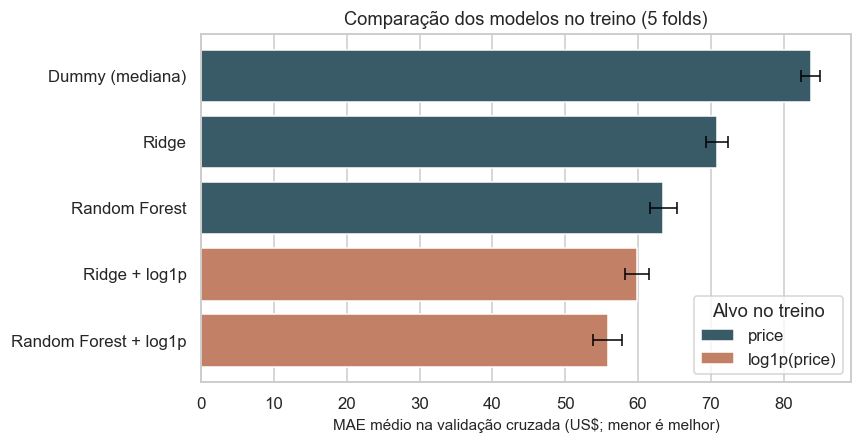

Modelo selecionado pelo treino/CV: Random Forest + log1p
MAE CV usado na seleção: $55.81


In [11]:
searches = {
    "Ridge": ridge_search,
    "Random Forest": forest_search,
    "Ridge + log1p": ridge_log_search,
    "Random Forest + log1p": forest_log_search,
}
rows = [{"modelo": "Dummy (mediana)", "alvo": "price", "mae_cv": dummy_folds.mean(), "desvio_cv": dummy_folds.std(ddof=1)}]
for name, search in searches.items():
    rows.append({
        "modelo": name,
        "alvo": "log1p(price)" if "log1p" in name else "price",
        "mae_cv": -search.best_score_,
        "desvio_cv": fold_mae(search).std(ddof=1),
    })
comparison = pd.DataFrame(rows)
display(comparison.style.format({"mae_cv": "${:,.2f}", "desvio_cv": "${:,.2f}"}))

fig, ax = plt.subplots(figsize=(8, 4.2))
sns.barplot(data=comparison, y="modelo", x="mae_cv", hue="alvo", dodge=False,
            palette={"price": AZUL, "log1p(price)": LARANJA}, ax=ax)
ax.errorbar(comparison["mae_cv"], range(len(comparison)), xerr=comparison["desvio_cv"],
            fmt="none", ecolor="black", capsize=4, linewidth=1)
ax.set(xlabel="MAE médio na validação cruzada (US$; menor é melhor)", ylabel="",
       title="Comparação dos modelos no treino (5 folds)")
ax.legend(title="Alvo no treino", loc="lower right")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "aps2_model_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

final_name = min(searches, key=lambda name: -searches[name].best_score_)
final_search = searches[final_name]
final_model = final_search.best_estimator_
final_uses_log = "log1p" in final_name
final_cv_mae = -final_search.best_score_
print("Modelo selecionado pelo treino/CV:", final_name)
print(f"MAE CV usado na seleção: ${final_cv_mae:.2f}")
RESULTS["comparacao"] = {
    row["modelo"]: {"mae_cv": float(row["mae_cv"]), "desvio_cv": float(row["desvio_cv"])} for row in rows
}
RESULTS["rf_log"] = {
    "mae_cv": float(forest_log_mae),
    "delta": float(delta),
    "delta_pct": float(100 * delta / -forest_search.best_score_),
    "folds_melhores": int((paired > 0).sum()),
    "params": {k: (None if v is None else float(v)) for k, v in clean_params(forest_log_search).items()},
}
RESULTS["ridge_log"] = {"mae_cv": float(-ridge_log_search.best_score_), "alpha": float(clean_params(ridge_log_search)["alpha"])}
RESULTS["final"] = {"modelo": final_name, "mae_cv": float(final_cv_mae)}

### 5.3 Os melhores valores ficaram no limite da grade?

Se o melhor valor de um hiperparâmetro é o menor ou o maior da grade, o ótimo pode estar fora dela. Conferimos isso para as quatro buscas.

In [12]:
edge_rows = []
for name, search in searches.items():
    grid = RIDGE_PARAMS if "Ridge" in name else RF_PARAMS
    for param, values in grid.items():
        best = clean_params(search)[param]
        ordered = [v for v in values if v is not None] + ([None] if None in values else [])
        # Limite natural: não existe valor além dele (profundidade ilimitada, folha de 1 anúncio, todas as colunas)
        natural = (param == "max_depth" and best is None) or (param == "min_samples_leaf" and best == 1)             or (param == "max_features" and best == 1.0)
        edge_rows.append({
            "modelo": name, "hiperparâmetro": param, "melhor valor": best,
            "no limite da grade": bool(best == ordered[0] or best == ordered[-1]),
            "é limite natural do hiperparâmetro": bool(natural),
        })
edge_table = pd.DataFrame(edge_rows)
display(edge_table)
RESULTS["limite_grade"] = edge_rows

,modelo,hiperparâmetro,melhor valor,no limite da grade,é limite natural do hiperparâmetro
0,Ridge,alpha,100.0,False,False
1,Random Forest,max_depth,NaN,True,True
2,Random Forest,min_samples_leaf,5.0,False,False
3,Random Forest,max_features,0.2,False,False
4,Ridge + log1p,alpha,10.0,False,False
5,Random Forest + log1p,max_depth,20.0,False,False
6,Random Forest + log1p,min_samples_leaf,1.0,True,True
7,Random Forest + log1p,max_features,0.2,False,False


**Resultado.** Com `log1p(price)` o MAE CV da floresta cai de US$ 63,42 para US$ 55,81 (−US$ 7,61, −12,0%), e a versão com log foi melhor em 5 dos 5 folds. A melhora ocorreu nos cinco folds usados, mas os folds compartilham dados de treino; essa consistência não equivale a cinco replicações independentes nem a um teste de significância. A mesma transformação ajuda o Ridge ainda mais: US$ 70,78 para US$ 59,87 (−US$ 10,91).

Um detalhe que muda a leitura: o **Ridge com log (US$ 59,87) já é melhor que a floresta sem log (US$ 63,42)**. Trocar o alvo valeu mais do que trocar o modelo linear por um ensemble. Com o log nos dois, a floresta continua na frente por US$ 4,06 no MAE médio e é selecionada por esse critério.

**Por que o log ajuda.** O preço tem cauda longa (assimetria de 19,12 na APS 1). No erro quadrático, que as árvores usam para dividir e o Ridge para ajustar, poucos anúncios de milhares de dólares dominam a perda e puxam o ajuste para longe do anúncio típico. No log, errar US$ 50 num anúncio de US$ 50 pesa mais do que errar US$ 50 num de US$ 500, e o modelo passa a acertar a escala dos preços comuns, que é o que o MAE mede para a maior parte da base.

**Por que no alvo e não como feature.** As variáveis de cauda longa já recebem `log1p` desde a APS 1. O que sobrou foi o alvo, e uma feature nova não muda o que o modelo é obrigado a minimizar; transformar o alvo, sim.

**O custo.** Minimizar erro quadrático em `log1p(price)` aproxima a média condicional do alvo transformado. Inverter essa média com `expm1` não recupera, em geral, a média condicional de `price`; tampouco garante a mediana condicional sem hipóteses adicionais sobre a distribuição. Duan (1983) discute o problema de retransformação. Aqui a adequação ao MAE é empírica: o erro de validação caiu após a nova busca. A subestimação dos preços altos é observada na seção 7.1, sem atribuir toda a sua causa ao log.

**Hiperparâmetros.** Depois do novo ajuste a floresta ficou com `max_features` = 0,20, `max_depth` = 20 e `min_samples_leaf` = 1. Só 2 melhores valores ficaram na borda da grade: `max_depth` = sem limite (Random Forest); `min_samples_leaf` = 1 (Random Forest + log1p). Nos dois casos a borda é o limite natural do hiperparâmetro (profundidade ilimitada; folha de um único anúncio), então não existe valor além dele para testar. Todos os outros ficaram no interior da grade.

## 6. Curva de aprendizado

Mantemos os hiperparâmetros escolhidos e variamos o tamanho do treino (de 20% a 100% do conjunto de treino, avaliando em cinco folds). Ela usa só dados de treino e o mesmo MAE. A curva mostra o hiato entre treino e validação e se mais dados ainda ajudariam.

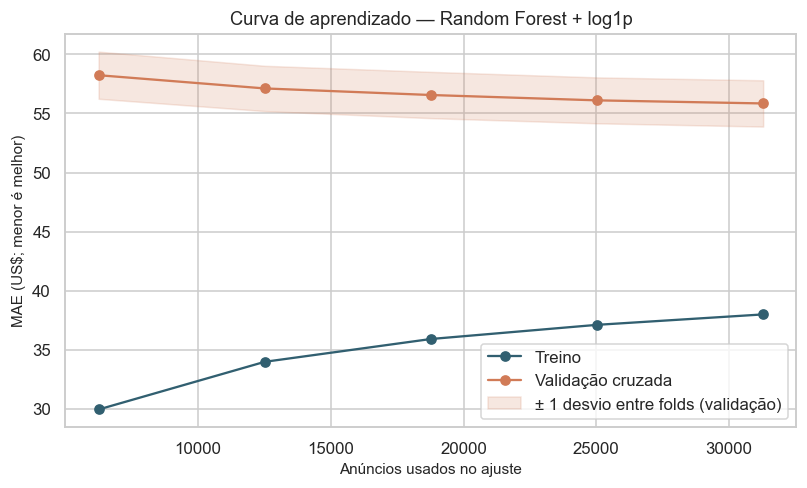

,anúncios no treino,MAE treino (US$),MAE validação (US$),desvio validação (US$)
0,6257,$29.96,$58.23,$1.99
1,12514,$33.99,$57.11,$1.91
2,18771,$35.92,$56.56,$1.96
3,25028,$37.12,$56.11,$1.94
4,31285,$38.00,$55.84,$1.96


Tempo da curva: 22 s


In [13]:
t0 = time.time()
train_sizes, train_scores, validation_scores = learning_curve(
    final_model, X_train, y_train,
    train_sizes=np.linspace(0.2, 1.0, 5), cv=CV, scoring=SCORING,
    n_jobs=1, shuffle=True, random_state=SEED,
)
train_mae = -train_scores.mean(axis=1)
validation_mae = -validation_scores.mean(axis=1)
validation_std = validation_scores.std(axis=1, ddof=1)

fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.plot(train_sizes, train_mae, marker="o", color=AZUL, label="Treino")
ax.plot(train_sizes, validation_mae, marker="o", color=LARANJA, label="Validação cruzada")
ax.fill_between(train_sizes, validation_mae - validation_std, validation_mae + validation_std,
                color=LARANJA, alpha=0.18, label="± 1 desvio entre folds (validação)")
ax.set(xlabel="Anúncios usados no ajuste", ylabel="MAE (US$; menor é melhor)",
       title=f"Curva de aprendizado — {final_name}")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "aps2_learning_curve.png", dpi=160, bbox_inches="tight")
plt.show()

learning_table = pd.DataFrame({
    "anúncios no treino": train_sizes,
    "MAE treino (US$)": train_mae,
    "MAE validação (US$)": validation_mae,
    "desvio validação (US$)": validation_std,
})
display(learning_table.style.format({
    "MAE treino (US$)": "${:,.2f}", "MAE validação (US$)": "${:,.2f}", "desvio validação (US$)": "${:,.2f}",
}))
print(f"Tempo da curva: {time.time() - t0:.0f} s")
RESULTS["curva"] = {
    "tamanhos": [int(v) for v in train_sizes],
    "mae_treino": [float(v) for v in train_mae],
    "mae_validacao": [float(v) for v in validation_mae],
}

**Leitura.** Com 6.257 anúncios no ajuste o MAE de validação é US$ 58,23; com 31.285 (todo o treino de cada fold) cai para US$ 55,84, ganho de US$ 2,39 com cinco vezes mais dados. O último trecho quase não anda: de 25.028 para 31.285 anúncios o erro caiu só US$ 0,26. O ganho marginal foi pequeno no intervalo observado; não extrapolamos esse resultado para qualquer volume ou perfil de dados novos.

O erro de treino sobe de US$ 29,96 para US$ 38,00 (mais dados são mais difíceis de memorizar), e o hiato até a validação diminui de US$ 28,28 para US$ 17,85, mas continua grande. Isso indica variância alta: as árvores profundas (`min_samples_leaf = 1`) se ajustam bem aos anúncios que viram. O erro de treino de uma floresta é otimista por construção, então parte do hiato é esperada.

**Consequência.** A curva sugere investigar regularização, atributos adicionais e dados mais representativos. Ela não identifica a causa do erro restante nem demonstra que mais features superarão mais linhas; essas alternativas exigem novos experimentos usando somente o treino para seleção.

## 7. Avaliação final no conjunto de teste

O modelo final foi escolhido sem consultar o teste. Agora reportamos o MAE uma vez no holdout e analisamos os três gráficos exigidos. Os resíduos são definidos como `real − previsto`: resíduo positivo significa que o modelo **subestimou** o preço.

Modelo final: Random Forest + log1p
MAE final no teste: $57.53  (MAE CV na seleção: $55.81)
MAE do Dummy (mediana) no teste: $85.93
Redução do erro frente ao Dummy: 33.1%
Número de anúncios no teste: 9,777
Resíduo médio: $+23.37; mediano: $-3.83; P1–P99: [$-121, $531]
Anúncios com erro absoluto ≤ US$ 25: 52.5%


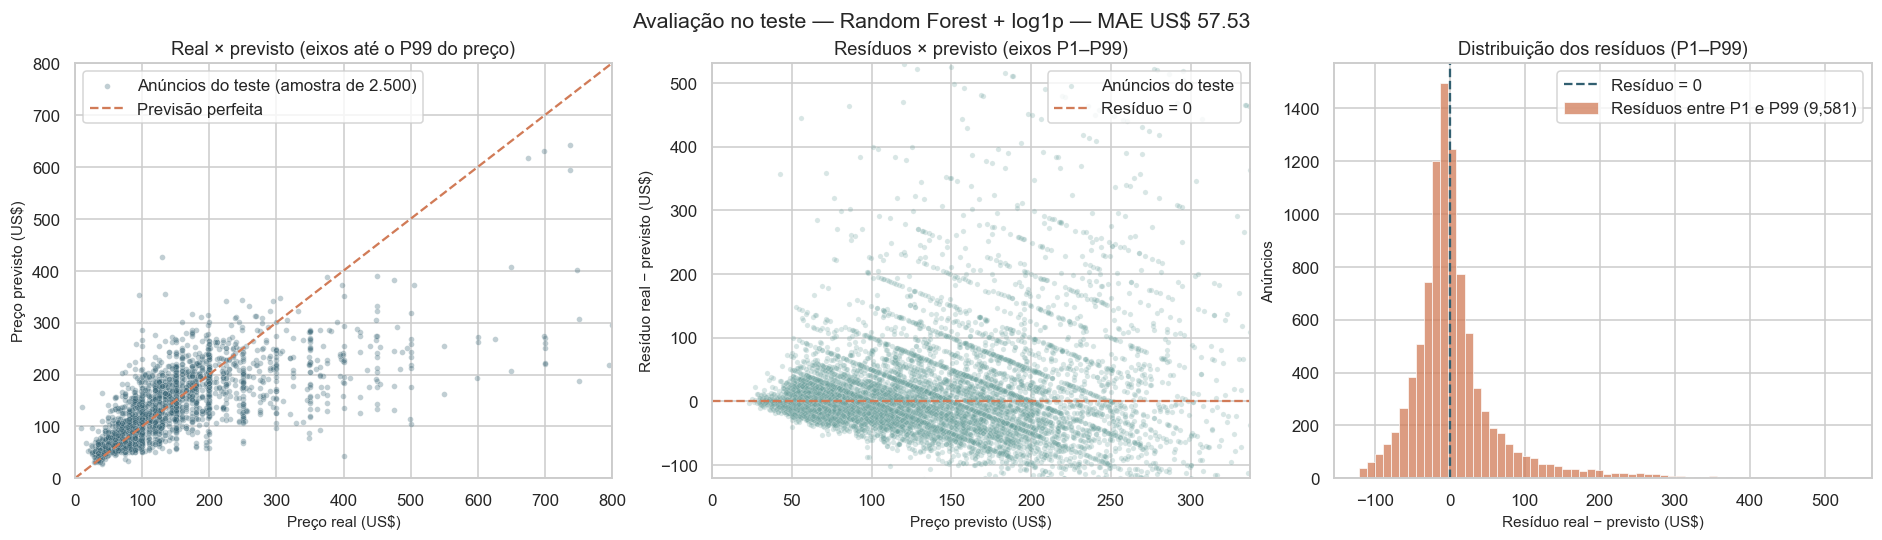

196 resíduos ficaram fora dos eixos dos gráficos; o MAE e as estatísticas acima incluem todos os anúncios.


In [14]:
y_pred = final_model.predict(X_test)
test_mae = mean_absolute_error(y_test, y_pred)
residuals = y_test.to_numpy() - y_pred
dummy_test_mae = mean_absolute_error(y_test, dummy_pipeline.fit(X_train, y_train).predict(X_test))
print("Modelo final:", final_name)
print(f"MAE final no teste: ${test_mae:.2f}  (MAE CV na seleção: ${final_cv_mae:.2f})")
print(f"MAE do Dummy (mediana) no teste: ${dummy_test_mae:.2f}")
print(f"Redução do erro frente ao Dummy: {100 * (1 - test_mae / dummy_test_mae):.1f}%")
print(f"Número de anúncios no teste: {len(y_test):,}")

lo, hi = np.quantile(residuals, [0.01, 0.99])
share_within_25 = float((np.abs(residuals) <= 25).mean() * 100)
print(f"Resíduo médio: ${residuals.mean():+.2f}; mediano: ${np.median(residuals):+.2f}; P1–P99: [${lo:.0f}, ${hi:.0f}]")
print(f"Anúncios com erro absoluto ≤ US$ 25: {share_within_25:.1f}%")

rng = np.random.default_rng(SEED)
sample = rng.choice(len(y_test), size=min(2500, len(y_test)), replace=False)
p99 = float(np.quantile(y_test, 0.99))
inside = (residuals >= lo) & (residuals <= hi)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)
sns.scatterplot(x=y_test.to_numpy()[sample], y=y_pred[sample], alpha=0.3, s=14, color=AZUL,
                ax=axes[0], label="Anúncios do teste (amostra de 2.500)")
axes[0].plot([0, p99], [0, p99], "--", color=LARANJA, label="Previsão perfeita")
axes[0].set(xlim=(0, p99), ylim=(0, p99), xlabel="Preço real (US$)", ylabel="Preço previsto (US$)",
            title="Real × previsto (eixos até o P99 do preço)")
axes[0].legend(loc="upper left")

sns.scatterplot(x=y_pred, y=residuals, alpha=0.25, s=12, color=VERDE, ax=axes[1],
                label="Anúncios do teste")
axes[1].axhline(0, linestyle="--", color=LARANJA, label="Resíduo = 0")
axes[1].set(xlim=(0, float(np.quantile(y_pred, 0.99))), ylim=(lo, hi),
            xlabel="Preço previsto (US$)", ylabel="Resíduo real − previsto (US$)",
            title="Resíduos × previsto (eixos P1–P99)")
axes[1].legend(loc="upper right")

sns.histplot(residuals[inside], bins=60, color=LARANJA, ax=axes[2], label=f"Resíduos entre P1 e P99 ({int(inside.sum()):,})")
axes[2].axvline(0, linestyle="--", color=AZUL, label="Resíduo = 0")
axes[2].set(xlabel="Resíduo real − previsto (US$)", ylabel="Anúncios", title="Distribuição dos resíduos (P1–P99)")
axes[2].legend(loc="upper right")
fig.suptitle(f"Avaliação no teste — {final_name} — MAE US$ {test_mae:,.2f}", fontsize=14)
fig.savefig(OUTPUT_DIR / "aps2_test_diagnostics.png", dpi=160, bbox_inches="tight")
plt.show()
print(f"{int((~inside).sum())} resíduos ficaram fora dos eixos dos gráficos; o MAE e as estatísticas acima incluem todos os anúncios.")
RESULTS["teste"] = {
    "mae": float(test_mae), "mae_dummy": float(dummy_test_mae),
    "residuo_medio": float(residuals.mean()), "residuo_mediano": float(np.median(residuals)),
    "residuo_p1": float(lo), "residuo_p99": float(hi), "erro_ate_25_pct": share_within_25,
    "fora_dos_eixos": int((~inside).sum()), "anuncios": int(len(y_test)),
}

**Resultado geral.** O MAE no teste é US$ 57,53, contra US$ 55,81 na validação cruzada: US$ 1,72 a mais (3,1%), menos que o desvio entre folds (US$ 1,95). As duas estimativas ficaram próximas neste experimento, mas a diferença não quantifica o viés de seleção: ela também pode refletir variação amostral. Selecionar e avaliar candidatos nos mesmos folds pode gerar otimismo (Cawley & Talbot, 2010), a ser investigado com avaliação aninhada ou repetida. O Dummy tem MAE de US$ 85,93 no teste, então o modelo final reduz o erro em 33,1%.

**Real × previsto.** Os pontos seguem a diagonal para preços até cerca de US$ 200; acima de US$ 300 a nuvem fica quase toda abaixo dela. O modelo satura: quase todas as previsões ficam abaixo de US$ 400, mesmo para anúncios que custam muito mais.

**Resíduos × previsto.** O funil abre para a direita: a dispersão dos resíduos cresce com o preço previsto (erro heterocedástico), então um mesmo MAE esconde incerteza bem diferente entre anúncios baratos e caros. As faixas diagonais descendentes são anúncios com o mesmo preço real (US$ 100, 150, 200, 250 e outros valores redondos): para preço real fixo, o resíduo `real − previsto` cai em linha reta com a previsão. Isso é compatível com preços anunciados em números redondos; não impede que uma previsão coincida com esses valores.

**Distribuição dos resíduos.** O pico fica perto de zero e a cauda direita é longa. O resíduo mediano é −US$ 3,83 (mais da metade dos anúncios é levemente superestimada), mas a média é US$ 23,37: poucos anúncios muito subestimados puxam a média para cima, efeito esperado de prever em log (seção 5). 52,5% dos anúncios têm erro absoluto de até US$ 25. Os gráficos mostram o intervalo entre P1 e P99 dos resíduos (de −US$ 121 a US$ 531); os 196 resíduos fora desse intervalo entram no MAE.

### 7.1 Erro por faixa de preço

O MAE agregado esconde diferenças entre anúncios baratos e caros. A tabela agrupa o teste em decis do preço real. Ela serve à discussão crítica e **não** é usada para reajustar o modelo.

In [15]:
errors = pd.DataFrame({"price_real": y_test.to_numpy(), "price_previsto": y_pred})
errors["erro_assinado"] = errors["price_real"] - errors["price_previsto"]
errors["erro_absoluto"] = errors["erro_assinado"].abs()
errors["decil_preco"] = pd.qcut(errors["price_real"], q=10, labels=False, duplicates="drop") + 1
by_decile = errors.groupby("decil_preco").agg(
    anuncios=("erro_absoluto", "size"),
    mediana_preco_real=("price_real", "median"),
    mae_usd=("erro_absoluto", "mean"),
    erro_assinado_usd=("erro_assinado", "mean"),
)
display(by_decile.style.format({
    "mediana_preco_real": "${:,.2f}", "mae_usd": "${:,.2f}", "erro_assinado_usd": "${:+,.2f}",
}))
top = errors.nlargest(1, "erro_absoluto").iloc[0]
tail = errors[errors["price_real"] >= 1000]
print(f"Anúncios com preço real ≥ US$ 1.000 no teste: {len(tail)} ({100 * len(tail) / len(errors):.2f}%); "
      f"respondem por {100 * tail['erro_absoluto'].sum() / errors['erro_absoluto'].sum():.1f}% do erro absoluto total")
print(f"MAE sem esses anúncios: ${errors.loc[errors['price_real'] < 1000, 'erro_absoluto'].mean():.2f}")
RESULTS["decis"] = {
    "mae": [float(v) for v in by_decile["mae_usd"]],
    "erro_assinado": [float(v) for v in by_decile["erro_assinado_usd"]],
    "mediana_preco": [float(v) for v in by_decile["mediana_preco_real"]],
}
RESULTS["cauda"] = {
    "n_ge_1000": int(len(tail)),
    "share_erro_pct": float(100 * tail["erro_absoluto"].sum() / errors["erro_absoluto"].sum()),
    "mae_sem_cauda": float(errors.loc[errors["price_real"] < 1000, "erro_absoluto"].mean()),
    "pior_real": float(top["price_real"]), "pior_previsto": float(top["price_previsto"]),
}

,anuncios,mediana_preco_real,mae_usd,erro_assinado_usd
decil_preco,,,,
1,1003,$40.00,$18.46,$-18.06
2,1007,$55.00,$15.26,$-13.37
3,1037,$70.00,$18.42,$-10.10
4,930,$85.00,$24.93,$-11.16
5,915,$100.00,$33.19,$-20.17
6,1046,$120.00,$34.19,$-14.91
7,910,$149.00,$37.57,$-11.76
8,987,$175.00,$38.84,$-0.39
9,966,$225.00,$50.02,$+30.87


Anúncios com preço real ≥ US$ 1.000 no teste: 62 (0.63%); respondem por 23.5% do erro absoluto total
MAE sem esses anúncios: $44.31


In [16]:
# Anúncios sem nenhuma avaliação: o modelo vê reviews = 0, como veria um anúncio recém-criado
errors["sem_avaliacoes"] = (X_test["number_of_reviews"].to_numpy() == 0)
by_reviews = errors.groupby("sem_avaliacoes").agg(
    anuncios=("erro_absoluto", "size"),
    mediana_preco_real=("price_real", "median"),
    mae_usd=("erro_absoluto", "mean"),
    erro_assinado_usd=("erro_assinado", "mean"),
)
by_reviews.index = by_reviews.index.map({False: "com avaliações", True: "sem avaliações"})
display(by_reviews.style.format({"mediana_preco_real": "${:,.2f}", "mae_usd": "${:,.2f}", "erro_assinado_usd": "${:+,.2f}"}))
RESULTS["avaliacoes"] = {
    idx: {"n": int(r.anuncios), "mae": float(r.mae_usd), "mediana_preco": float(r.mediana_preco_real), "erro_assinado": float(r.erro_assinado_usd)}
    for idx, r in by_reviews.iterrows()
}

,anuncios,mediana_preco_real,mae_usd,erro_assinado_usd
sem_avaliacoes,,,,
com avaliações,7782,$100.00,$48.35,$+16.37
sem avaliações,1995,$120.00,$93.34,$+50.66


**Onde o erro está.** Nos nove primeiros decis o MAE vai de US$ 15,26 a US$ 50,02. No decil mais caro (mediana de US$ 366) ele salta para US$ 306,67, com erro médio assinado de US$ 303,48: o modelo subestima quase tudo ali. Nos decis 1 a 7 o erro assinado é negativo (de −US$ 10,10 a −US$ 20,17): os baratos são levemente superestimados, e as previsões se comprimem para o centro da distribuição.

Os 62 anúncios com preço real a partir de US$ 1.000 (0,63% do teste) respondem por 23,5% de todo o erro absoluto; sem eles o MAE seria US$ 44,31. O pior caso é um anúncio de US$ 9.999 previsto em US$ 115.

**Para o negócio.** O modelo serve como referência de preço para a maioria dos anúncios (decis 1 a 8), mas não para os caros: um dono de imóvel de luxo receberia uma sugestão muito abaixo do valor real.

**Anúncios sem avaliações.** Há outra fonte de erro. Os 1.995 anúncios do teste sem nenhuma avaliação (20,4% do teste) têm MAE de US$ 93,34, contra US$ 48,35 dos 7.782 com avaliações, e erro assinado de US$ 50,66 contra US$ 16,37 (preço mediano US$ 120 contra US$ 100). Não separamos quanto disso vem de o modelo não ter o sinal de avaliações e quanto vem de esses anúncios terem outro perfil (por exemplo, novos ou inativos). A seção 12 volta a isso.

## 8. Interpretação: coeficientes do Ridge e importâncias da floresta

Duas leituras, de dois modelos diferentes (e cada análise diz qual): o **Ridge** (o melhor modelo linear pela validação cruzada) e a **Random Forest** final, a mesma usada no SHAP da seção 9.

No Ridge, as variáveis numéricas entram padronizadas (média 0, desvio 1) e as categorias entram como colunas 0/1 (one-hot). Como o encoding mantém todas as categorias (`drop=None`), não há uma categoria omitida como referência. Um contraste entre duas categorias do mesmo atributo usa a diferença entre seus coeficientes, quando a comparação é compatível com as demais entradas. O coeficiente de uma numérica corresponde a **um desvio-padrão** da variável após as transformações. Para comparar na mesma régua, mostramos também o coeficiente multiplicado pelo desvio-padrão da coluna no treino.

Modelo: Ridge + log1p(price) — coeficientes em unidades de log1p(price)


,feature,coeficiente,coef × desvio-padrão,anúncios na categoria (treino),efeito aproximado no preço
136,room_type = Entire home/apt,+0.611,+0.305,"20,278",+84%
11,neighbourhood_group = Staten Island,-0.557,-0.048,295,-43%
122,neighbourhood = Tribeca,+0.529,+0.033,150,+70%


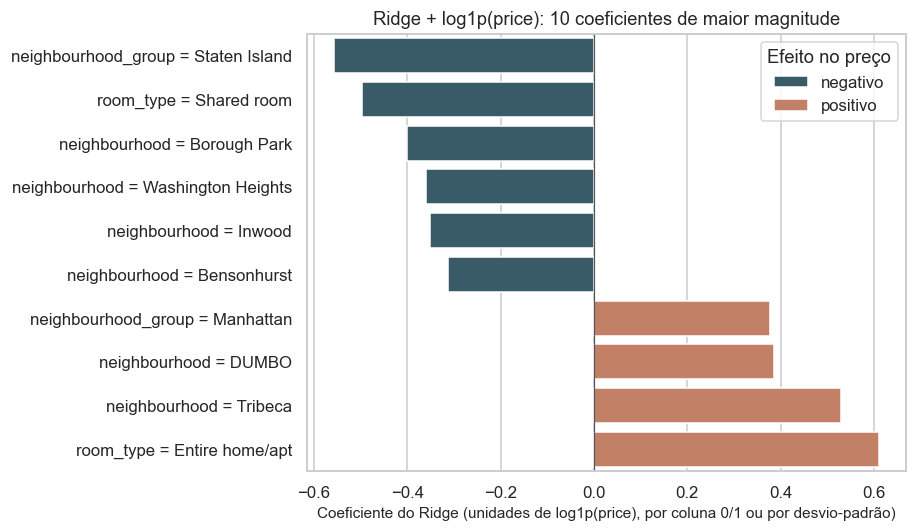

Maiores coeficientes entre as variáveis numéricas (padronizadas):


,feature,coeficiente
6,availability_365,+0.124
5,longitude,-0.103
0,minimum_nights,-0.093


In [17]:
# ---- Ridge: o melhor modelo linear pela validação cruzada
ridge_uses_log = -ridge_log_search.best_score_ < -ridge_search.best_score_
ridge_label = "Ridge + log1p(price)" if ridge_uses_log else "Ridge"
ridge_fitted = (ridge_log_search.best_estimator_.regressor_ if ridge_uses_log else ridge_search.best_estimator_)
ridge_pre = ridge_fitted.named_steps["preprocessor"]
ridge_names = get_preprocessed_feature_names(ridge_pre)
ridge_matrix = ridge_pre.transform(X_train)
ridge_coef = ridge_fitted.named_steps["model"].coef_
is_category = np.array([name.startswith("categorical__") for name in ridge_names])

ridge_table = pd.DataFrame({
    "feature": [display_feature_name(n) for n in ridge_names],
    "coeficiente": ridge_coef,
    "coef × desvio-padrão": ridge_coef * ridge_matrix.std(axis=0),
    "anúncios na categoria (treino)": np.where(is_category, ridge_matrix.sum(axis=0), np.nan),
})
unit = "log1p(price)" if ridge_uses_log else "US$"
ridge_top3 = ridge_table.reindex(ridge_table["coeficiente"].abs().sort_values(ascending=False).index).head(3)
if ridge_uses_log:
    ridge_top3 = ridge_top3.assign(**{"efeito aproximado no preço": 100 * (np.exp(ridge_top3["coeficiente"]) - 1)})
print(f"Modelo: {ridge_label} — coeficientes em unidades de {unit}")
fmt = {"coeficiente": "{:+.3f}", "coef × desvio-padrão": "{:+.3f}", "anúncios na categoria (treino)": "{:,.0f}"}
if ridge_uses_log:
    fmt["efeito aproximado no preço"] = "{:+.0f}%"
display(ridge_top3.style.format(fmt, na_rep="—"))

ridge_top10 = ridge_table.reindex(ridge_table["coeficiente"].abs().sort_values(ascending=False).index).head(10)
ridge_top10 = ridge_top10.assign(sinal=np.where(ridge_top10["coeficiente"] > 0, "positivo", "negativo")).sort_values("coeficiente")
fig, ax = plt.subplots(figsize=(8.5, 5))
sns.barplot(data=ridge_top10, y="feature", x="coeficiente", hue="sinal", dodge=False,
            palette={"positivo": LARANJA, "negativo": AZUL}, ax=ax)
ax.axvline(0, color="#555555", linewidth=0.8)
ax.set(xlabel=f"Coeficiente do Ridge (unidades de {unit}, por coluna 0/1 ou por desvio-padrão)", ylabel="",
       title=f"{ridge_label}: 10 coeficientes de maior magnitude")
ax.legend(title="Efeito no preço", loc="upper right")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "aps2_ridge_coefficients.png", dpi=160, bbox_inches="tight")
plt.show()

top_numeric = ridge_table[~is_category].reindex(
    ridge_table[~is_category]["coeficiente"].abs().sort_values(ascending=False).index).head(3)
print("Maiores coeficientes entre as variáveis numéricas (padronizadas):")
display(top_numeric[["feature", "coeficiente"]].style.format({"coeficiente": "{:+.3f}"}))
RESULTS["ridge"] = {
    "modelo": ridge_label, "unidade": unit,
    "top3": [{"feature": r.feature, "coef": float(r.coeficiente),
              "n": None if np.isnan(r._4) else float(r._4)} for r in ridge_top3.itertuples()],
    "top_numericas": [{"feature": r.feature, "coef": float(r.coeficiente)} for r in top_numeric.itertuples()],
}

**De qual modelo vem.** Ridge + log1p(price), o melhor modelo linear pela validação cruzada (MAE CV US$ 59,87, `alpha` = 10). Como o alvo foi `log1p(price)`, os coeficientes estão em unidades de `log1p(price)`, **não em dólares**: aumentar uma coluna em uma unidade, mantendo as outras fixas, multiplica a previsão de `price + 1` por `exp(c)`. Para preços suficientemente acima de zero, `100·(exp(c) − 1)`% aproxima a variação de preço. Porém, alternar isoladamente uma coluna one-hot cria uma entrada inválida; o contraste entre categorias do mesmo atributo usa a diferença dos coeficientes. Este é o modelo linear (MAE CV US$ 59,87), não o modelo final (floresta, US$ 55,81), então a tabela explica o Ridge.

**Os três maiores coeficientes.**

1. `room_type = Entire home/apt`: 0,611 (≈ 84%), com 20.278 anúncios no treino. O coeficiente positivo é compatível com as medianas maiores da APS 1. O percentual isolado não é um prêmio estimado contra quarto privado: esse contraste exige subtrair o coeficiente da outra categoria. É a maior magnitude por coluna e a categoria reúne mais da metade do treino.
2. `neighbourhood_group = Staten Island`: −0,557 (≈ −43%), com 295 anúncios (0,75% do treino). O sinal é negativo no ajuste regularizado; não corresponde a um desconto identificado contra Manhattan, pois bairro e coordenadas também codificam localização.
3. `neighbourhood = Tribeca`: +0,529 (≈ +70%), com 150 anúncios (0,38% do treino). O sinal é positivo no ajuste, mas a amostra pequena e a sobreposição com borough e coordenadas limitam sua interpretação isolada.

**Cuidado com as escalas.** Os três são colunas 0/1 (a categoria existe ou não), enquanto as numéricas entram padronizadas, e o coeficiente delas é por um desvio-padrão. Comparar um com o outro direto engana. Na mesma régua (coeficiente × desvio-padrão da coluna no treino), Entire home/apt vale 0,305, Staten Island −0,048 e Tribeca 0,033, contra 0,124 de `availability_365`, a maior numérica. O tipo de acomodação continua sendo o efeito dominante, mas Staten Island e Tribeca perdem peso: o efeito por anúncio é grande, mas poucos anúncios pertencem a essas categorias.

**Categoria rara.** Tribeca aparece no top 3 com 150 anúncios. O coeficiente é uma estimativa de um grupo pequeno e deve ser lido com menos confiança que o de `room_type`; a regularização L2 restringe os coeficientes, mas uma magnitude alta não prova um efeito de mercado estável nem causal. O `min_frequency=20` da APS 1 deixou esse bairro entrar no modelo; já o Ridge não tem uma categoria de referência, então os coeficientes de um mesmo grupo se leem como contrastes entre categorias.

As relações são condicionais e associativas, não causais.

Modelo: Random Forest + log1p — importância de impureza (soma = 1)


,feature,variável original,importância
136,room_type = Entire home/apt,room_type,0.2297
137,room_type = Private room,room_type,0.1485
5,longitude,longitude,0.1472


,variável original,importância
0,room_type,0.3992
1,longitude,0.1472
2,latitude,0.1042
3,neighbourhood,0.0704
4,availability_365,0.0671
5,neighbourhood_group,0.0556
6,minimum_nights,0.0465
7,reviews_per_month,0.0419
8,number_of_reviews,0.0357
9,calculated_host_listings_count,0.0320


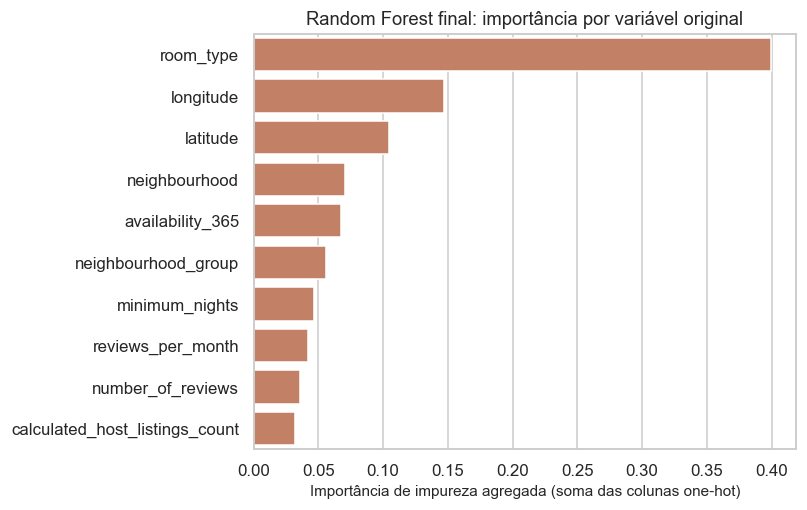

In [18]:
# ---- Random Forest final: importâncias de impureza (do modelo final, o mesmo do SHAP)
final_pipeline = final_model.regressor_ if final_uses_log else final_model
final_estimator = final_pipeline.named_steps["model"]
if not isinstance(final_estimator, RandomForestRegressor):
    raise TypeError("As análises abaixo assumem que o modelo final é a Random Forest.")
final_preprocessor = final_pipeline.named_steps["preprocessor"]
final_feature_names = get_preprocessed_feature_names(final_preprocessor)
final_display_names = [display_feature_name(n) for n in final_feature_names]
final_original_names = np.array([original_feature_name(n) for n in final_feature_names])

forest_table = pd.DataFrame({
    "feature": final_display_names,
    "variável original": final_original_names,
    "importância": final_estimator.feature_importances_,
}).sort_values("importância", ascending=False)
print(f"Modelo: {final_name} — importância de impureza (soma = 1)")
display(forest_table.head(3).style.format({"importância": "{:.4f}"}))

forest_grouped = forest_table.groupby("variável original", as_index=False)["importância"].sum().sort_values(
    "importância", ascending=False).reset_index(drop=True)
display(forest_grouped.head(10).style.format({"importância": "{:.4f}"}))

fig, ax = plt.subplots(figsize=(7.5, 4.8))
sns.barplot(data=forest_grouped.head(10), y="variável original", x="importância", color=LARANJA, ax=ax)
ax.set(xlabel="Importância de impureza agregada (soma das colunas one-hot)", ylabel="",
       title=f"Random Forest final: importância por variável original")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "aps2_forest_importance.png", dpi=160, bbox_inches="tight")
plt.show()
RESULTS["floresta"] = {
    "top3_colunas": [{"feature": r.feature, "imp": float(r.importância)} for r in forest_table.head(3).itertuples()],
    "agregada": {r._1: float(r.importância) for r in forest_grouped.head(10).itertuples()},
}

**De qual modelo vem.** Da Random Forest final (`Random Forest + log1p`), a mesma usada no SHAP. A importância é a de impureza: o quanto cada coluna reduz o erro quadrático (no alvo log) nas divisões das árvores; as importâncias somam 1.

**Os três maiores valores por coluna:** `room_type = Entire home/apt` (0,230), `room_type = Private room` (0,149) e `longitude` (0,147). As duas primeiras são o mesmo `room_type` em duas colunas one-hot quase complementares (casa inteira e quarto privado são quase toda a base), então a lista por coluna conta a mesma variável duas vezes. Somando por variável original, `room_type` fica com 0,399 de toda a importância, seguido de `longitude` (0,147), `latitude` (0,104), `neighbourhood` (0,070) e `availability_365` (0,067).

**O que significam para o preço.** O tipo de acomodação é a divisão que mais separa preços (casa inteira contra quarto), de acordo com a APS 1. Latitude e longitude juntas somam 0,251, quase tanto quanto o tipo: as árvores recriam a geografia por cortes sucessivos em coordenadas, e a região define uma parte grande do preço. `neighbourhood` aparece baixo, mas está dividido em dezenas de colunas one-hot, e as coordenadas já dão uma localização mais fina. Fazem sentido: tipo e localização são o que se esperaria de um mercado imobiliário.

**Limites desta medida.** A importância de impureza tende a favorecer variáveis com muitos pontos de corte possíveis (Strobl et al., 2007), é calculada nos dados de treino e não informa a direção do efeito. Por isso conferimos com SHAP: `availability_365` sobe de 0,067 (5ª) para 0,092 (3ª) e `neighbourhood` cai de 0,070 para 0,040. O resultado é associativo, não causal.

## 9. Explicabilidade com SHAP

Usamos o `TreeExplainer` na Random Forest final (a mesma da seção 8). A importância global é a média de `|SHAP|` em uma amostra fixa de 250 anúncios de treino, somando as colunas one-hot de cada variável original em cada anúncio antes de tirar o módulo. Em seguida explicamos três previsões do teste: a de maior subestimação, a de maior superestimação e uma com erro absoluto próximo da mediana.

Como o modelo final foi treinado com `log1p(price)`, os valores SHAP estão na escala `log1p(price)`: a soma dos valores SHAP mais o valor-base dá a previsão em `log1p(price)`, e `expm1` devolve dólares. Uma contribuição de +0,10 equivale a cerca de +10,5% no preço previsto. As atribuições descrevem o modelo, não relações causais.

,média de |SHAP| (log1p(price))
room_type,0.371604
longitude,0.127907
availability_365,0.092142
neighbourhood_group,0.086094
latitude,0.066784
minimum_nights,0.046530
neighbourhood,0.039733
number_of_reviews,0.027810
reviews_per_month,0.026196
calculated_host_listings_count,0.012970


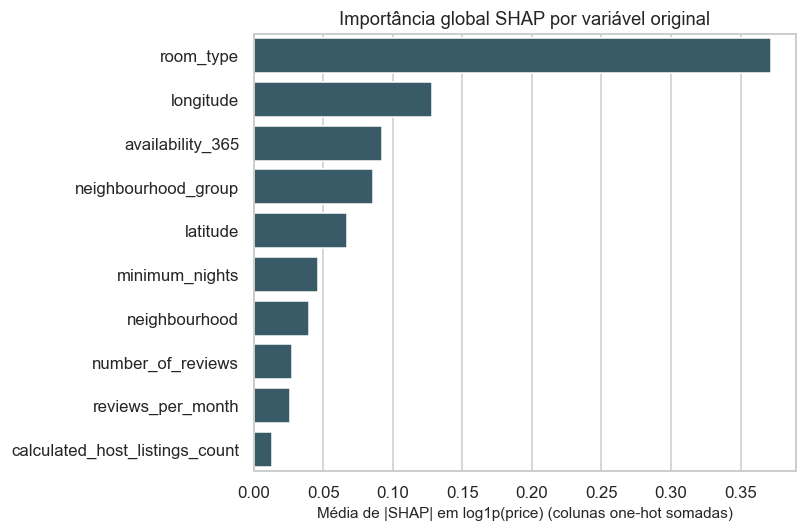

Tempo do SHAP global: 355 s


In [19]:
t0 = time.time()
explainer = shap.TreeExplainer(final_estimator, feature_perturbation="tree_path_dependent",
                               feature_names=final_display_names)
global_raw = X_train.sample(n=250, random_state=SEED)
global_shap = explainer(final_preprocessor.transform(global_raw))
explanation_scale = "log1p(price)" if final_uses_log else "US$"

orig_unique = list(dict.fromkeys(final_original_names))
shap_grouped = pd.DataFrame({
    col: global_shap.values[:, final_original_names == col].sum(axis=1) for col in orig_unique
})
mean_abs_shap = shap_grouped.abs().mean().sort_values(ascending=False)
display(mean_abs_shap.head(10).rename(f"média de |SHAP| ({explanation_scale})").to_frame())

fig, ax = plt.subplots(figsize=(7.5, 5))
shap_plot = mean_abs_shap.head(10).rename_axis("variável").reset_index(name="shap")
sns.barplot(data=shap_plot, y="variável", x="shap", color=AZUL, ax=ax)
ax.set(xlabel=f"Média de |SHAP| em {explanation_scale} (colunas one-hot somadas)", ylabel="",
       title="Importância global SHAP por variável original")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "aps2_shap_global.png", dpi=160, bbox_inches="tight")
plt.show()
print(f"Tempo do SHAP global: {time.time() - t0:.0f} s")
RESULTS["shap_global"] = {k: float(v) for k, v in mean_abs_shap.head(10).items()}

**Leitura.** As variáveis, na ordem, são `room_type` (0,372), `longitude` (0,128), `availability_365` (0,092), `neighbourhood_group` (0,086) e `latitude` (0,067). A contribuição absoluta média de `room_type` na saída logarítmica é cerca de 2,9 vezes a de longitude. Não podemos convertê-la em uma variação média de ±45%: o módulo perde o sinal e a exponenciação é não linear.

**Em relação à importância de impureza:** o topo é o mesmo (tipo de acomodação e localização), mas `availability_365` e `neighbourhood_group` ganham posições, e `neighbourhood` perde. Como o SHAP mede o efeito sobre a previsão de cada anúncio, e não só o ganho nas divisões, ele é uma leitura mais direta do que o modelo usa. `availability_365` é a terceira: o número de dias em que o imóvel fica disponível é escolha do anfitrião e provavelmente separa anúncios de uso ocasional dos de oferta profissional (a APS 1 viu associação com `calculated_host_listings_count`); é uma hipótese, não algo que o modelo comprove. As variáveis de avaliações pesam pouco (`number_of_reviews` 0,028 e `reviews_per_month` 0,026).

Os valores são do modelo final, na escala log; as atribuições descrevem o modelo, não relações causais (Lundberg et al., 2020).

,caso,preço real (US$),preço previsto (US$),resíduo real − previsto (US$),valor-base E[f(X)],f(x) em log1p
0,maior subestimação,"$9,999",$115.27,"$+9,883.73",4.738,4.756
1,maior superestimação,$180,$567.16,$-387.16,4.738,6.342
2,erro absoluto mediano,$133,$156.25,$-23.25,4.738,5.058


Preço base (expm1 do valor-base): $113.17

Caso 1 — maior subestimação


,variável,valor do anúncio,SHAP (log1p),efeito no preço previsto
0,room_type,Entire home/apt,+0.324,+38%
1,longitude,-73.938980,-0.180,-16%
2,availability_365,0,-0.127,-12%
3,neighbourhood,East Harlem,-0.050,-5%



Caso 2 — maior superestimação


,variável,valor do anúncio,SHAP (log1p),efeito no preço previsto
0,room_type,Entire home/apt,+0.407,+50%
1,neighbourhood,Tribeca,+0.352,+42%
2,longitude,-74.007090,+0.342,+41%
3,neighbourhood_group,Manhattan,+0.177,+19%



Caso 3 — erro absoluto mediano


,variável,valor do anúncio,SHAP (log1p),efeito no preço previsto
0,room_type,Entire home/apt,+0.367,+44%
1,minimum_nights,30,-0.161,-15%
2,latitude,40.774670,+0.087,+9%
3,neighbourhood_group,Manhattan,+0.073,+8%


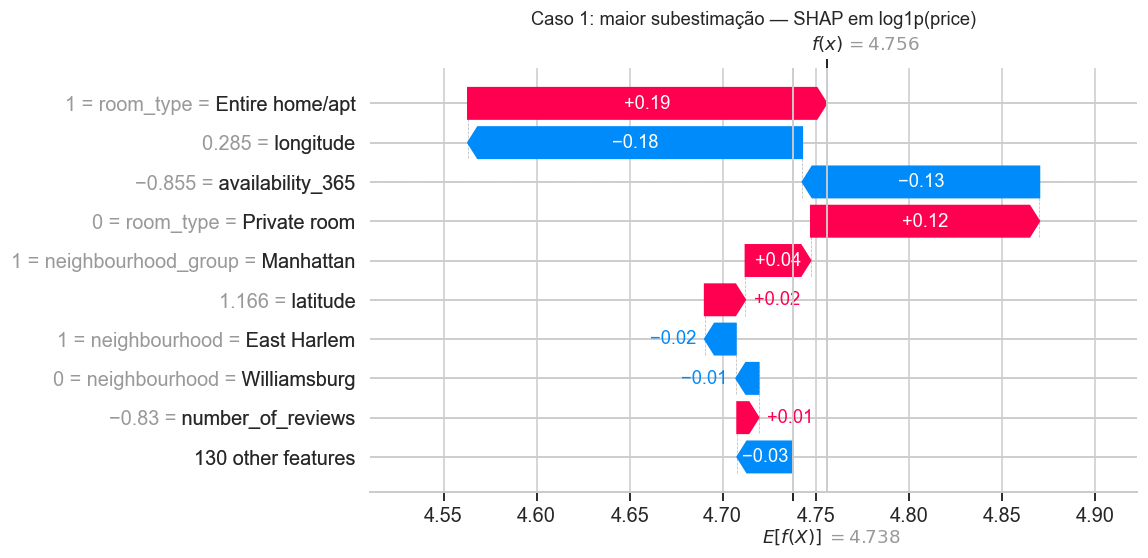

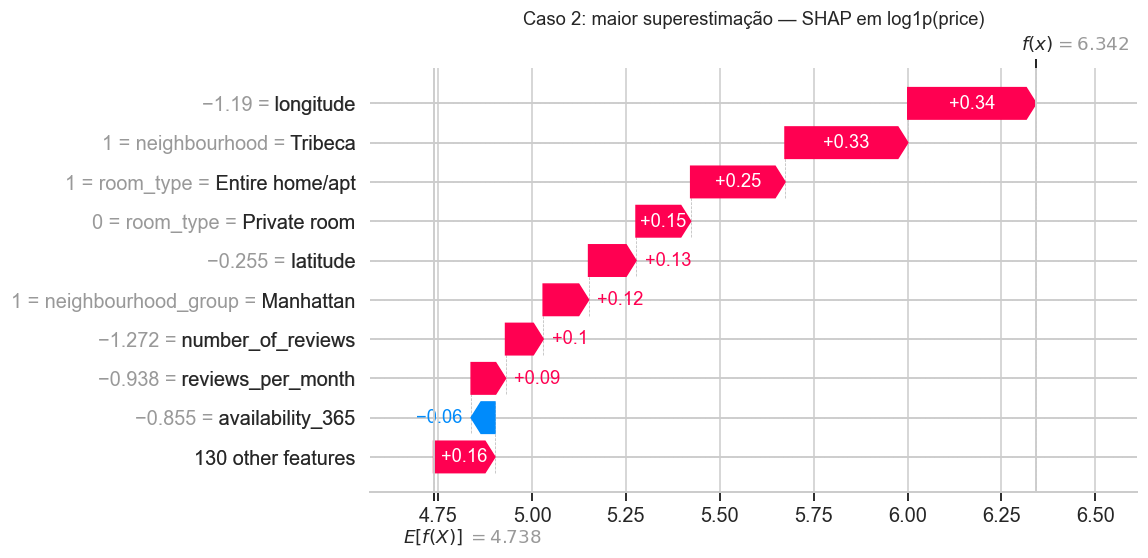

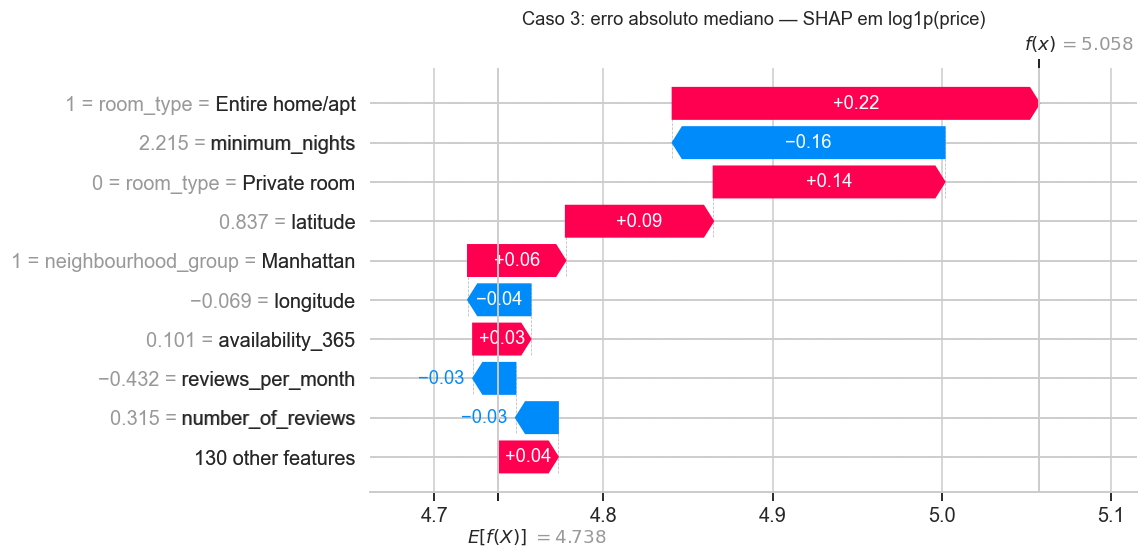

In [20]:
abs_res = np.abs(residuals)
local_positions = [
    int(np.argmax(residuals)),                                  # maior subestimação (real >> previsto)
    int(np.argmin(residuals)),                                  # maior superestimação (previsto >> real)
    int(np.argmin(np.abs(abs_res - np.median(abs_res)))),       # erro absoluto mais próximo da mediana
]
case_labels = ["maior subestimação", "maior superestimação", "erro absoluto mediano"]
local_raw = X_test.iloc[local_positions]
local_shap = explainer(final_preprocessor.transform(local_raw))

local_summary = pd.DataFrame({
    "caso": case_labels,
    "preço real (US$)": y_test.iloc[local_positions].to_numpy(),
    "preço previsto (US$)": y_pred[local_positions],
    "resíduo real − previsto (US$)": residuals[local_positions],
    "valor-base E[f(X)]": float(np.ravel(explainer.expected_value)[0]),
    "f(x) em log1p": [float(local_shap[i].base_values + local_shap[i].values.sum()) for i in range(3)],
})
display(local_summary.style.format({
    "preço real (US$)": "${:,.0f}", "preço previsto (US$)": "${:,.2f}",
    "resíduo real − previsto (US$)": "${:+,.2f}", "valor-base E[f(X)]": "{:.3f}", "f(x) em log1p": "{:.3f}",
}))
print(f"Preço base (expm1 do valor-base): ${np.expm1(local_summary['valor-base E[f(X)]'][0]):.2f}")

# Contribuição por variável original (one-hot somado), com o valor cru do anúncio
local_top = {}
for i, (label, position) in enumerate(zip(case_labels, local_positions)):
    values = local_shap[i].values
    row = X_test.iloc[position]
    by_variable = pd.Series({col: values[final_original_names == col].sum() for col in orig_unique})
    top = by_variable.reindex(by_variable.abs().sort_values(ascending=False).index).head(4)
    table = pd.DataFrame({
        "variável": top.index,
        "valor do anúncio": [row[c] for c in top.index],
        "SHAP (log1p)": top.to_numpy(),
        "efeito no preço previsto": 100 * (np.exp(top.to_numpy()) - 1),
    })
    print(f"\nCaso {i + 1} — {label}")
    display(table.style.format({"SHAP (log1p)": "{:+.3f}", "efeito no preço previsto": "{:+.0f}%"}))
    local_top[label] = table

for i, label in enumerate(case_labels, start=1):
    shap.plots.waterfall(local_shap[i - 1], max_display=10, show=False)
    fig = plt.gcf()
    fig.set_size_inches(9, 5)
    plt.title(f"Caso {i}: {label} — SHAP em {explanation_scale}")
    fig.savefig(OUTPUT_DIR / f"aps2_shap_case_{i}.png", dpi=160, bbox_inches="tight")
    plt.show()
RESULTS["shap_casos"] = {
    label: {
        "real": float(y_test.iloc[p]), "previsto": float(y_pred[p]),
        "top": [{"variavel": r.variável, "valor": (r._2 if isinstance(r._2, str) else float(r._2)),
                 "shap": float(r._3), "efeito_pct": float(r._4)} for r in local_top[label].itertuples()],
    }
    for label, p in zip(case_labels, local_positions)
}
RESULTS["shap_base"] = float(np.ravel(explainer.expected_value)[0])

**Como ler.** O valor-base (a previsão média) é 4,738 em `log1p(price)`, equivalente a US$ 113,17. Cada contribuição empurra a previsão para cima ou para baixo, e a variável que mais pesa em cada caso vem listada com o valor do anúncio, a contribuição em `log1p` e o efeito aproximado no preço. As colunas one-hot de cada variável aparecem somadas nas listas de texto, com o valor original do anúncio; os gráficos mostram cada coluna separada e os valores das numéricas já padronizados (depois do `log1p` e da escala), por isso `minimum_nights = 30` aparece como 2,215 no caso 3.

**Caso 1 — maior subestimação** (real US$ 9.999, previsto US$ 115,27). Maiores contribuições: `room_type` = Entire home/apt: 0,324 (+38%); `longitude` = −73,939: −0,180 (−16%); `availability_365` = 0: −0,127 (−12%); `neighbourhood` = East Harlem: −0,050 (−5%). Em conjunto elas quase se cancelam, e a previsão fica perto do valor-base. A explicação do modelo é coerente (casa inteira empurra o preço para cima; um anúncio sem nenhuma disponibilidade no ano e no leste do Harlem empurra para baixo), mas nada nas variáveis disponíveis justifica um preço de quase US$ 10.000. O anúncio tem preço extremo. Erro de cadastro, preço simbólico, características ausentes e limitações do modelo são hipóteses; o SHAP não permite decidir entre elas nem atestar que a lógica do modelo está correta.

**Caso 2 — maior superestimação** (real US$ 180, previsto US$ 567,16). Maiores contribuições: `room_type` = Entire home/apt: 0,407 (+50%); `neighbourhood` = Tribeca: 0,352 (+42%); `longitude` = −74,007: 0,342 (+41%); `neighbourhood_group` = Manhattan: 0,177 (+19%). Todas empurram para cima: casa inteira em Tribeca, em Manhattan. É o perfil clássico de um anúncio caro, e o modelo o trata como tal. O preço real de US$ 180 é baixo para esse perfil, o que indica algo não observado (tamanho, estado do imóvel, preço promocional). Também aparece uma redundância: Tribeca, longitude e `neighbourhood_group = Manhattan` descrevem a mesma região, e as atribuições positivas são distribuídas entre atributos geográficos relacionados. Isso não demonstra tripla contagem indevida; a atribuição com preditores dependentes depende das hipóteses do explicador.

**Caso 3 — erro mediano** (real US$ 133, previsto US$ 156,25). Maiores contribuições: `room_type` = Entire home/apt: 0,367 (+44%); `minimum_nights` = 30: −0,161 (−15%); `latitude` = 40,775: 0,087 (+9%); `neighbourhood_group` = Manhattan: 0,073 (+8%). A previsão é coerente: casa inteira em Manhattan sobe o preço, e uma estadia mínima de 30 noites o reduz. A explicação provável para isso é que anúncios de aluguel mensal costumam ter diária menor, mas essa leitura é uma hipótese, não algo que o modelo comprove. O erro absoluto é US$ 23,25, próximo da mediana observada; classificá-lo como aceitável exigiria um critério de uso definido.

**Padrão.** Nos três casos `room_type` é a maior contribuição positiva (de +38% a +50%), e os erros grandes aparecem quando o preço real foge do que tipo e localização preveem.

## 10. Sensibilidade: anúncios com `minimum_nights > 365`

A APS 1 prometeu comparar o desempenho com e sem os 14 anúncios de estadia mínima acima de um ano, que ficaram na base. Aqui retreinamos o modelo final **com os mesmos hiperparâmetros** sem esses anúncios (somente no treino) e avaliamos no teste oficial. Repetimos com três sementes da floresta para separar o efeito da remoção do ruído do sorteio das árvores. O split oficial e o modelo final não mudam; é só uma análise de sensibilidade.

In [21]:
def final_pipeline_like(seed):
    # Mesma configuração do modelo final, com outra semente da floresta
    forest = RandomForestRegressor(n_estimators=200, random_state=seed, n_jobs=-1, **{
        k: v for k, v in clean_params(final_search).items()})
    return build_log_target_pipeline(forest) if final_uses_log else build_model_pipeline(forest)


keep = X_train["minimum_nights"] <= 365
test_keep = X_test["minimum_nights"] <= 365
print(f"Anúncios com minimum_nights > 365: {int((~keep).sum())} no treino e {int((~test_keep).sum())} no teste")
rows = []
for seed in (42, 7, 123):
    full = final_pipeline_like(seed).fit(X_train, y_train)
    reduced = final_pipeline_like(seed).fit(X_train[keep], y_train[keep])
    rows.append({
        "semente": seed,
        "com todos — teste completo": mean_absolute_error(y_test, full.predict(X_test)),
        "sem >365 no treino — teste completo": mean_absolute_error(y_test, reduced.predict(X_test)),
        "com todos — teste sem >365": mean_absolute_error(y_test[test_keep], full.predict(X_test[test_keep])),
        "sem >365 no treino — teste sem >365": mean_absolute_error(y_test[test_keep], reduced.predict(X_test[test_keep])),
    })
sens_nights = pd.DataFrame(rows).set_index("semente")
display(sens_nights.style.format("${:,.2f}"))
sens_mean = sens_nights.mean()
display(sens_mean.to_frame("média das 3 sementes").style.format("${:,.2f}"))
RESULTS["sens_noites"] = {
    "treino_removidos": int((~keep).sum()), "teste_com_365": int((~test_keep).sum()),
    "media": {k: float(v) for k, v in sens_mean.items()},
    "desvio_entre_sementes_com_todos": float(sens_nights["com todos — teste completo"].std(ddof=1)),
}

Anúncios com minimum_nights > 365: 12 no treino e 2 no teste


,com todos — teste completo,sem >365 no treino — teste completo,com todos — teste sem >365,sem >365 no treino — teste sem >365
semente,,,,
42,$57.53,$57.53,$57.53,$57.53
7,$57.44,$57.51,$57.44,$57.52
123,$57.47,$57.48,$57.47,$57.48


,média das 3 sementes
com todos — teste completo,$57.48
sem >365 no treino — teste completo,$57.51
com todos — teste sem >365,$57.48
sem >365 no treino — teste sem >365,$57.51


**Resultado.** Há 12 anúncios com `minimum_nights > 365` no treino e só 2 no teste. Com três sementes de floresta, o MAE de teste médio é US$ 57,48 com todos os anúncios e US$ 57,51 sem eles no treino: diferença de US$ 0,03, menor que a variação entre sementes (US$ 0,04). Avaliando só os anúncios com `minimum_nights <= 365` o resultado é o mesmo (US$ 57,48 contra US$ 57,51).

**Conclusão.** Manter esses 12 anúncios não prejudica nem ajuda o desempenho; a decisão da APS 1 (manter e comprimir com `log1p`) se sustenta. Com apenas 2 casos no teste, não dá para dizer nada sobre o desempenho nos próprios anúncios de estadia muito longa.

## 11. Sensibilidade: divisão por anfitrião (`GroupKFold`) contra divisão por linha

Na seção 3 vimos que parte dos anfitriões do teste também está no treino. Para medir se isso deixa a estimativa otimista, repetimos a validação cruzada **só no treino**, com os hiperparâmetros finais fixos, de dois jeitos: `KFold` por linha (o que usamos) e `GroupKFold` com `host_id` como grupo (nenhum anfitrião aparece em treino e validação ao mesmo tempo). Repetimos com cinco sementes de embaralhamento. O split oficial continua sendo o por linha, para manter a comparabilidade com a APS 1.

In [22]:
t0 = time.time()
groups = X_train["host_id"]
model_for_cv = final_pipeline_like(SEED)
rows = []
for seed in range(5):
    row_cv = -cross_val_score(model_for_cv, X_train, y_train, scoring=SCORING,
                              cv=KFold(5, shuffle=True, random_state=seed))
    group_cv = -cross_val_score(model_for_cv, X_train, y_train, scoring=SCORING, groups=groups,
                                cv=GroupKFold(5, shuffle=True, random_state=seed))
    rows.append({"semente": seed, "KFold por linha": row_cv.mean(), "GroupKFold por host_id": group_cv.mean()})
host_table = pd.DataFrame(rows).set_index("semente")
host_table["diferença"] = host_table["GroupKFold por host_id"] - host_table["KFold por linha"]
display(host_table.style.format("${:+,.2f}", subset=["diferença"]).format("${:,.2f}", subset=["KFold por linha", "GroupKFold por host_id"]))
print(f"Média por linha: ${host_table['KFold por linha'].mean():.2f}; por host_id: ${host_table['GroupKFold por host_id'].mean():.2f}")
print(f"Diferença média: ${host_table['diferença'].mean():+.2f} ± ${host_table['diferença'].std(ddof=1):.2f} "
      f"({100 * host_table['diferença'].mean() / host_table['KFold por linha'].mean():+.1f}%); "
      f"o erro por host foi maior em {int((host_table['diferença'] > 0).sum())} de 5 sementes")
print(f"Tempo: {time.time() - t0:.0f} s")
RESULTS["sens_host"] = {
    "linha": float(host_table["KFold por linha"].mean()),
    "grupo": float(host_table["GroupKFold por host_id"].mean()),
    "dif_media": float(host_table["diferença"].mean()),
    "dif_desvio": float(host_table["diferença"].std(ddof=1)),
    "dif_pct": float(100 * host_table["diferença"].mean() / host_table["KFold por linha"].mean()),
    "sementes_pior": int((host_table["diferença"] > 0).sum()),
}

,KFold por linha,GroupKFold por host_id,diferença
semente,,,
0,$55.77,$58.66,$+2.89
1,$55.80,$58.47,$+2.67
2,$55.73,$58.38,$+2.64
3,$55.78,$58.31,$+2.53
4,$55.85,$58.27,$+2.42


Média por linha: $55.79; por host_id: $58.42
Diferença média: $+2.63 ± $0.18 (+4.7%); o erro por host foi maior em 5 de 5 sementes
Tempo: 247 s


**Resultado.** Com os mesmos hiperparâmetros, o MAE da validação cruzada é US$ 55,79 dividindo por linha e US$ 58,42 dividindo por anfitrião: US$ 2,63 a mais (4,7%), com desvio de US$ 0,18 entre as 5 sementes. O erro por anfitrião foi maior nas cinco sementes testadas, evidência consistente neste experimento, sem constituir prova de ausência de variação amostral.

**Interpretação.** Anúncios do mesmo anfitrião provavelmente têm preço e perfil parecidos, e o modelo parece aproveitar isso quando vê o anfitrião no treino (no split oficial, 31,0% dos anúncios de teste têm anfitrião também presente no treino). O `host_id` não é variável de entrada, mas `calculated_host_listings_count`, coordenadas e tipo podem funcionar como substitutos do anfitrião. A dependência por anfitrião é uma possível fonte de otimismo. A diferença de 4,7% foi medida dentro do treino, com hiperparâmetros selecionados pelo protocolo por linha e mantidos fixos. Não demonstra vazamento temporal nem deve ser aplicada como correção exata ao MAE do teste ou a futuros anfitriões novos. O split oficial segue por linha, igual à APS 1.

## 12. Discussão crítica

As duas limitações do modelo e as duas dos dados abaixo são diferentes das que já aparecem no trabalho (erro nos anúncios caros e subestimação na seção 7, risco por anfitrião e estadias longas nas seções 10 e 11, 2019, preço anunciado, categorias pequenas e variáveis ausentes na APS 1).

### Limitações do modelo

1. **Previsão pontual, sem incerteza.** O modelo devolve um único valor por anúncio. Mas o erro depende muito do tipo de anúncio: o MAE vai de US$ 15,26 a US$ 306,67 entre decis, e o funil dos resíduos abre com o preço previsto. Quem recebe a sugestão não sabe se é confiável. Uma extensão com florestas de regressão quantílica pode estimar quantis condicionais (Meinshausen, 2006), o que permitiria devolver um intervalo (por exemplo, de 10% a 90%) e sinalizar os anúncios em que a previsão é pouco confiável. Não fizemos isso aqui.
2. **Seleção de modelo na mesma validação cruzada que reporta o desempenho.** Escolhemos entre 4 modelos e várias combinações de hiperparâmetros com o MAE CV, e a busca da floresta olha só 20 das 144 combinações. Escolher o melhor entre muitos candidatos nos mesmos folds gera um otimismo de seleção (Cawley & Talbot, 2010). A diferença de US$ 1,72 entre MAE CV (US$ 55,81) e teste (US$ 57,53) não estima esse viés isoladamente, porque também reflete diferenças amostrais. O teste reservado fornece a avaliação após a seleção, ainda com incerteza da amostra. Uma validação cruzada aninhada reduziria o viés, ao custo de várias vezes o tempo de execução, e não foi feita.

### Limitações dos dados

1. **Variáveis que só existem depois que o anúncio funciona (partida a frio).** `number_of_reviews` e `reviews_per_month` são consequência de o anúncio já ter recebido hóspedes; para um anúncio novo elas são sempre zero. Na base, 20,4% dos anúncios do teste não têm avaliações, e neles o MAE é US$ 93,34, contra US$ 48,35 dos demais (seção 7.1). Usar na previsão informação que não existe no momento da decisão é uma forma de vazamento (Kaufman et al., 2012). O peso dessas variáveis no modelo é baixo, e a diferença de MAE também pode vir do perfil desses anúncios, então não conseguimos atribuí-la só a essas variáveis. Para uso em anúncios novos o certo é retreinar só com o que o anfitrião informa no cadastro (tipo, localização, estadia mínima, disponibilidade).
2. **Dependência espacial entre anúncios.** Anúncios vizinhos compartilham demanda, acesso e preços, e a validação aleatória deixa vizinhos dos dois lados. Em dados com estrutura espacial ou hierárquica, a validação aleatória subestima o erro de previsão para locais novos (Roberts et al., 2017). Latitude e longitude são das variáveis mais importantes aqui (0,147 e 0,104 de importância), então o risco é relevante. Medimos o efeito do anfitrião, mas não o do bloco geográfico (por exemplo, `GroupKFold` por células de latitude e longitude), e isso fica como próximo passo.

### Ações para operacionalização e manutenção

1. **Empacotar e versionar o pipeline inteiro.** Salvar em um único artefato (por exemplo, `joblib`, conforme a documentação de persistência do scikit-learn) o pré-processador e o modelo, com as versões de Python e bibliotecas, o hash do arquivo de dados, a semente e os hiperparâmetros, mais as métricas de referência (MAE CV US$ 55,81, teste US$ 57,53 e por decil). Validar o esquema de entrada (colunas, tipos, valores nulos) antes de prever. Isso evita o custo escondido de dependências de dados e configuração que Sculley et al. (2015) descrevem em sistemas de ML, e permite reproduzir qualquer previsão antiga.
2. **Monitorar deriva e definir gatilho de retreino.** O mercado muda (sazonalidade, regras, eventos) e os dados são de 2019. Acompanhar mês a mês a distribuição das entradas e do preço contra a do treino, e, quando os preços observados chegarem, o MAE geral e por faixa de preço (principalmente os caros e os sem avaliações). Quando o erro passar de um limite combinado com o negócio, ou a distribuição se afastar do treino, retreinar com dados recentes. Essa deriva do conceito (a relação entre atributos e preço muda) é descrita por Gama et al. (2014) e se encaixa na etapa de gerenciamento do NIST AI RMF.

## 13. Conclusões

O modelo final é a Random Forest treinada com `log1p(price)`: MAE de US$ 55,81 na validação cruzada e US$ 57,53 no teste, contra US$ 85,93 do Dummy (33,1% menos erro). A mudança no pipeline foi o que mais pesou: o `log1p` no alvo reduziu o erro da floresta em 12,0% e fez até o Ridge (US$ 59,87) superar a floresta sem log (US$ 63,42).

Tipo de acomodação e localização explicam o essencial do que o modelo usa, de forma consistente entre Ridge, importâncias da floresta e SHAP. Três limites mudam como o resultado deve ser lido: o erro se concentra nos anúncios caros (decil mais alto com MAE de US$ 306,67); a validação por anfitrião teve MAE 4,7% maior dentro do treino, sem quantificar exatamente o erro de anfitriões novos; e anúncios sem avaliações têm erro quase o dobro. Remover as estadias de mais de um ano não muda o desempenho. Os próximos passos mais úteis seriam estimar intervalos de previsão, retreinar só com variáveis do cadastro para anúncios novos e validar por blocos geográficos.

In [23]:
RESULTS["tempo_execucao_min"] = round((time.time() - START_TIME) / 60, 1)
(PROJECT_ROOT / "reports" / "aps2_results.json").write_text(
    json.dumps(RESULTS, indent=2, ensure_ascii=False, default=float), encoding="utf8")
summary = pd.Series({
    "modelo final": final_name,
    "MAE validação cruzada (US$)": final_cv_mae,
    "MAE teste (US$)": test_mae,
    "MAE Dummy no teste (US$)": dummy_test_mae,
    "MAE CV Random Forest sem log (US$)": -forest_search.best_score_,
    "MAE CV Random Forest com log (US$)": forest_log_mae,
}, name="resultado")
display(summary)
print(f"Tempo total de execução: {RESULTS['tempo_execucao_min']} min")

modelo final                          Random Forest + log1p
MAE validação cruzada (US$)                       55.812568
MAE teste (US$)                                    57.52774
MAE Dummy no teste (US$)                          85.927483
MAE CV Random Forest sem log (US$)                63.421216
MAE CV Random Forest com log (US$)                55.812568
Name: resultado, dtype: object

Tempo total de execução: 20.8 min


## Referências

- Kaggle. *New York City Airbnb Open Data*. https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data
- Pedregosa, F. et al. (2011). *Scikit-learn: Machine Learning in Python*. JMLR, 12, 2825–2830.
- Scikit-learn. *Pipeline and composite estimators* (inclui `TransformedTargetRegressor`). https://scikit-learn.org/stable/modules/compose.html
- Scikit-learn. *GridSearchCV*, *RandomizedSearchCV* e *GroupKFold*. https://scikit-learn.org/stable/modules/cross_validation.html
- Scikit-learn. *Mean absolute error*. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_absolute_error.html
- Scikit-learn. *Learning curves*. https://scikit-learn.org/stable/modules/learning_curve.html
- Scikit-learn. *Model persistence*. https://scikit-learn.org/stable/model_persistence.html
- Lundberg, S. M., & Lee, S. I. (2017). *A Unified Approach to Interpreting Model Predictions*. NeurIPS. https://papers.nips.cc/paper/2017/hash/8a20a8621978632d76c43dfd28b67767-Abstract.html
- Lundberg, S. M. et al. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence*, 2(1), 56–67.
- Duan, N. (1983). Smearing estimate: a nonparametric retransformation method. *Journal of the American Statistical Association*, 78(383), 605–610. https://doi.org/10.2307/2288126
- Strobl, C., Boulesteix, A.-L., Zeileis, A., & Hothorn, T. (2007). Bias in random forest variable importance measures: Illustrations, sources and a solution. *BMC Bioinformatics*, 8, 25. https://doi.org/10.1186/1471-2105-8-25
- Cawley, G. C., & Talbot, N. L. C. (2010). On over-fitting in model selection and subsequent selection bias in performance evaluation. *JMLR*, 11, 2079–2107. https://www.jmlr.org/papers/v11/cawley10a.html
- Meinshausen, N. (2006). Quantile regression forests. *JMLR*, 7, 983–999. https://www.jmlr.org/papers/v7/meinshausen06a.html
- Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data*, 6(4), art. 15.
- Roberts, D. R. et al. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography*, 40(8), 913–929. https://doi.org/10.1111/ecog.02881
- Sculley, D. et al. (2015). Hidden technical debt in machine learning systems. *NeurIPS*, 28, 2503–2511. https://proceedings.neurips.cc/paper/2015/file/86df7dcfd896fcaf2674f757a2463eba-Paper.pdf
- Gama, J., Žliobaitė, I., Bifet, A., Pechenizkiy, M., & Bouchachia, A. (2014). A survey on concept drift adaptation. *ACM Computing Surveys*, 46(4), art. 44. https://doi.org/10.1145/2523813
- NIST. *AI Risk Management Framework Playbook — Manage*. https://airc.nist.gov/airmf-resources/playbook/manage/